In [ ]:
!pip install numpy pandas matplotlib seaborn

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import random

In [ ]:
maze = [
    "S.......",
    "######..",
    "........",
    "..######",
    "........",
    "######..",
    "........",
    ".......G"
]

grid = np.array([list(row) for row in maze])

In [ ]:
S = tuple(np.argwhere(grid == "S")[0])
G = tuple(np.argwhere(grid == "G")[0])

In [ ]:
A = [(-1,0), (1,0), (0,-1), (0,1)]

In [ ]:
Q = np.zeros((8,8,4))
rewards = []
steps = []

In [ ]:
random.seed(42)
np.random.seed(42)

In [ ]:
for ep in range(2000):
  s = S
  total = 0

  for step in range(200):

    #Epsilon-Greedy Action Selection
    if random.random() < 0.1:                             #Exploration
      a = random.randrange(4)
    else:                                                 #Exploitation
      best = np.flatnonzero(Q[s]==Q[s].max())
      a = random.choice(best.tolist())

    #Current Position
    r, c = s

    #Calculate Next Position
    nr = r + A[a][0]
    nc = c + A[a][1]

    #Checks walls and boundaries
    if not (0 <= nr < 8 and 0 <= nc < 8) or (grid[nr][nc] == "#"):
      ns = s
      reward = -5
      done = False
    else:
      ns = (nr,nc)
      done = (ns == G)
      if done:
        reward = 100
      else:
        reward = -1

    #Q-learning Update Equation
    Q[s][a] += 0.1 * (
        reward
        + 0.95 * (0 if done else Q[ns].max())
        - Q[s][a]
    )

    #Update reward and current state
    total += reward
    s = ns
    if done:
      break

  #Store training results
  rewards.append(total)
  steps.append(step + 1)


In [ ]:
#Find Learned Path
s = S
path = [S]
visited = {S}

for _ in range(64):
  #Select best learned action
  a = np.argmax(Q[s])
  r,c = s
  nr = r + A[a][0]
  nc = c + A[a][1]

  # Stop if movement is invalid
  if not (0 <= nr < 8 and 0 <= nc < 8) or grid[nr][nc] == "#":
    break;
  s = (nr,nc)

  # Stop if position is repeated
  if s in visited:
    break
  path.append(s)
  visited.add(s)

  #Stop when the goal is reached
  if s == G:
    break
print("Goal Reached:",path[-1]==G)
print("Path:",path)



Goal Reached: True
Path: [(np.int64(0), np.int64(0)), (np.int64(0), np.int64(1)), (np.int64(0), np.int64(2)), (np.int64(0), np.int64(3)), (np.int64(0), np.int64(4)), (np.int64(0), np.int64(5)), (np.int64(0), np.int64(6)), (np.int64(1), np.int64(6)), (np.int64(2), np.int64(6)), (np.int64(2), np.int64(5)), (np.int64(2), np.int64(4)), (np.int64(2), np.int64(3)), (np.int64(2), np.int64(2)), (np.int64(2), np.int64(1)), (np.int64(3), np.int64(1)), (np.int64(4), np.int64(1)), (np.int64(4), np.int64(2)), (np.int64(4), np.int64(3)), (np.int64(4), np.int64(4)), (np.int64(4), np.int64(5)), (np.int64(4), np.int64(6)), (np.int64(4), np.int64(7)), (np.int64(5), np.int64(7)), (np.int64(6), np.int64(7)), (np.int64(7), np.int64(7))]


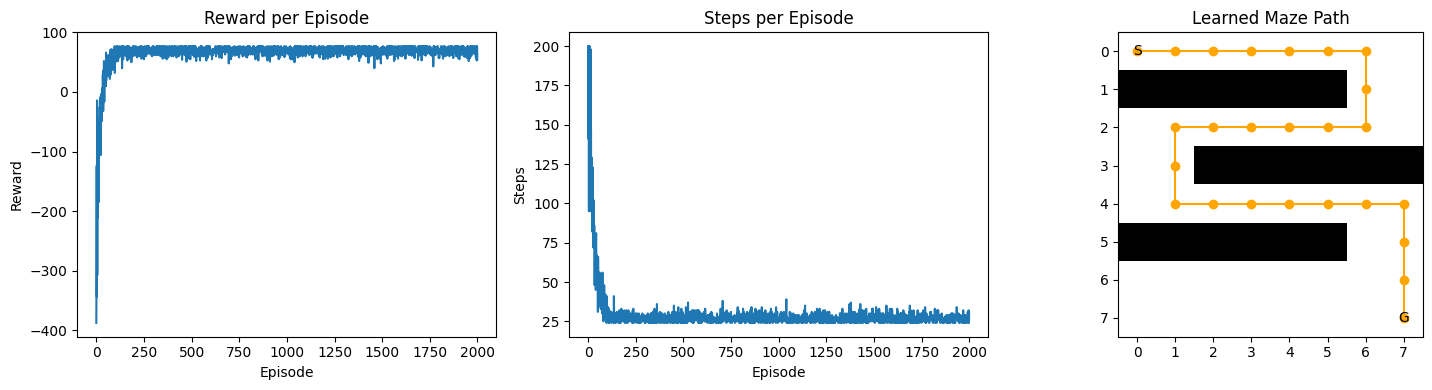

In [ ]:
# 5. Display graphs and learned path
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# Graph 1: Reward per episode
ax[0].plot(rewards)
ax[0].set_title("Reward per Episode")
ax[0].set_xlabel("Episode")
ax[0].set_ylabel("Reward")

# Graph 2: Steps per episode
ax[1].plot(steps)
ax[1].set_title("Steps per Episode")
ax[1].set_xlabel("Episode")
ax[1].set_ylabel("Steps")

# Graph 3: Learned maze path
ax[2].imshow(grid == "#", cmap="Greys")
ax[2].set_title("Learned Maze Path")
ax[2].set_xticks(range(8))
ax[2].set_yticks(range(8))

# Display start and goal
for r in range(8):
    for c in range(8):
        if grid[r, c] != "#":

            if (r, c) == S:
                label = "S"
            elif (r, c) == G:
                label = "G"
            else:
                label = ""

            ax[2].text(c, r, label,
                       ha="center", va="center")

# Draw learned path
y, x = zip(*path)
ax[2].plot(x, y, "o-", color="orange")

plt.tight_layout()
plt.show()